In [3]:

# ============================================================
# PROJECT 4: MESSAGE INTELLIGENCE SYSTEM
# SUPERVISED LEARNING - SPAM CLASSIFICATION
# ============================================================

# Data Manipulation
import pandas as pd
import numpy as np

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer

# Classification Models
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

# Model Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    roc_curve,
    auc
)

# Distance Metrics
from sklearn.metrics import pairwise_distances

# Model Utilities
from sklearn.pipeline import Pipeline

# Save Model
import joblib

# Streamlit Support
import streamlit as st

from sklearn.svm import SVC

# Ignore Warnings
import warnings
warnings.filterwarnings('ignore')

# Display Settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

# Visualization Theme
sns.set_theme(style="whitegrid")

# Nude Color Palette
NUDE_COLORS = [
    '#E8DCCB',
    '#D6C3AD',
    '#BFA58A',
    '#A88970',
    '#8C715D',
    '#6F5748'
]

# Plot Settings
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.facecolor'] = '#FAF7F2'
plt.rcParams['figure.facecolor'] = '#FAF7F2'
plt.rcParams['axes.edgecolor'] = '#BFA58A'
plt.rcParams['text.color'] = '#594638'
plt.rcParams['axes.labelcolor'] = '#594638'
plt.rcParams['xtick.color'] = '#594638'
plt.rcParams['ytick.color'] = '#594638'
plt.rcParams['axes.titlecolor'] = '#594638'

print("All Libraries Imported Successfully!")
print("Project 4: Message Intelligence System")
print("Theme: Professional Nude Beige")


All Libraries Imported Successfully!
Project 4: Message Intelligence System
Theme: Professional Nude Beige



# 🧠 Part A: Probability & Conceptual Foundation

## 🧠 Task 1: What is Conditional Probability?

**Answer:**

Conditional Probability is the probability of an event occurring when another event has already occurred. It is calculated using the probability of both events.

**Formula:**

$$
P(A|B) = \frac{P(A \cap B)}{P(B)}
$$

**Example:** The probability that a message is Spam given that it contains a suspicious URL.

---

## 🧠 Task 2: Explain Bayes' Theorem and its importance in classification problems.

**Answer:**

Bayes' Theorem is used to calculate the probability of an event based on previously known information. It helps classifiers predict the probability of a message belonging to a particular class.

**Formula:**

$$
P(A|B) = \frac{P(B|A) \times P(A)}{P(B)}
$$

**Importance:** It helps identify whether a message is Spam or Legitimate based on its features.

---

## 🧠 Task 3: What assumptions does the Naive Bayes Classifier make?

**Answer:**

Naive Bayes assumes that all input features are conditionally independent of each other given the target class. It uses Bayes' Theorem to calculate the probability of each class.

It is simple, fast, and effective for many classification problems.

---

## 🧠 Task 4: Explain the working principle of KNN and SVM.

### A. K-Nearest Neighbors (KNN)

**Answer:**

KNN is a distance-based classification algorithm that identifies the nearest K data points to a new data point. It assigns the class based on the majority vote of its nearest neighbors.

### B. Support Vector Machine (SVM)

**Answer:**

SVM is a margin-based classification algorithm that finds the best decision boundary (hyperplane) to separate different classes. It uses support vectors to maximize the margin between classes.

---

## 🧠 Task 5: Compare Distance-Based, Probabilistic, and Margin-Based Classifiers.

**Answer:**

| Classifier Type | Working Principle | Example |
|---|---|---|
| Distance-Based | Classifies using distances between data points. | KNN |
| Probabilistic | Predicts classes using probability calculations. | Naive Bayes |
| Margin-Based | Finds the best boundary to separate classes. | SVM |

**Conclusion:** Each classifier uses a different approach to classification. KNN depends on distance, Naive Bayes depends on probability, and SVM depends on margin separation.

---

## 📝 Part A – Final Conclusion

In this part, we studied the basic concepts of probability, Bayes' Theorem, and classification algorithms.

We understood the working principles of KNN, SVM, and Naive Bayes and learned how these algorithms classify messages using different techniques.


---

# 📂 Part B: Dataset Understanding & Preparation

---



## 📂 Task 6: Identify Input Features and Target Variable

Identify the input features (X) and target variable (y) 
required for the Spam Classification Model.


In [4]:

# 📂 Task 6: Load Dataset

df = pd.read_excel("../Dataset/Message_spam.xlsx")

# Display First Five Rows
df.head()


,message_id,message_text,message_length,word_count,num_urls,num_digits,num_special_chars,spam_keyword_score,legit_keyword_score,sender_activity_score,sender_account_age_days,messages_sent_last_24h,timestamp,hour_of_day,day_of_week,spam_label
0,900001,Please find the attached invoice for the updat...,99,11,1,4,0,0,1,56.6,500.0,6.0,2025-11-24 02:00:00,2,0,0
1,900002,Let's catch up tomorrow regarding the timeline...,73,12,0,0,0,0,0,16.6,207.0,0.0,2025-12-17 21:00:00,21,2,0
2,900003,Can you send the report by end of day? next Mo...,67,13,0,0,0,0,1,25.7,418.0,6.0,2025-11-15 13:00:00,13,5,0
3,900004,Can you send the report by end of day? 10:30 A...,64,13,0,4,0,0,1,48.8,276.0,5.0,2025-12-17 23:00:00,23,2,0
4,900005,Could you review the document and share feedba...,84,14,0,0,0,0,1,33.0,683.0,7.0,2025-11-29 11:00:00,11,5,0


In [5]:

# 📂 Task 6: Identify Input Features and Target Variable

X = df[
    [
        'message_length',
        'word_count',
        'num_urls',
        'num_digits',
        'num_special_chars',
        'spam_keyword_score',
        'legit_keyword_score',
        'sender_activity_score',
        'sender_account_age_days',
        'messages_sent_last_24h',
        'hour_of_day',
        'day_of_week'
    ]
]

y = df['spam_label']

print("Input Features Shape:", X.shape)
print("Target Variable Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())


Input Features Shape: (5200, 12)
Target Variable Shape: (5200,)

Target Distribution:
spam_label
0    4227
1     973
Name: count, dtype: int64


In [6]:

# 📂 Task 6: Identify Input Features and Target Variable


# 📂 Task 6: Load Dataset

df = pd.read_excel("../Dataset/Message_spam.xlsx")

# Display First Five Rows
df.head()

X = df[
    [
        'message_length',
        'word_count',
        'num_urls',
        'num_digits',
        'num_special_chars',
        'spam_keyword_score',
        'legit_keyword_score',
        'sender_activity_score',
        'sender_account_age_days',
        'messages_sent_last_24h',
        'hour_of_day',
        'day_of_week'
    ]
]

y = df['spam_label']

print("Input Features Shape:", X.shape)
print("Target Variable Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())


Input Features Shape: (5200, 12)
Target Variable Shape: (5200,)

Target Distribution:
spam_label
0    4227
1     973
Name: count, dtype: int64



### Conclusion

Input features and the target variable were successfully identified.



## 📂 Task 7: Perform Basic Data Preprocessing

Perform basic data preprocessing by identifying missing values and preparing input features for classification.


In [7]:

# 📂 Task 7: Basic Data Preprocessing

# Select Input Features
X = df[
    [
        'message_length',
        'word_count',
        'num_urls',
        'num_digits',
        'num_special_chars',
        'spam_keyword_score',
        'legit_keyword_score',
        'sender_activity_score',
        'sender_account_age_days',
        'messages_sent_last_24h',
        'hour_of_day',
        'day_of_week'
    ]
]

# Select Target Variable
y = df['spam_label']

# Check Missing Values
print("Missing Values:")
print(X.isnull().sum())

# Total Missing Values
print("\nTotal Missing Values:", X.isnull().sum().sum())

# Check Duplicate Records
print("\nDuplicate Records:", df.duplicated().sum())


Missing Values:
message_length               0
word_count                   0
num_urls                     0
num_digits                   0
num_special_chars            0
spam_keyword_score           0
legit_keyword_score          0
sender_activity_score      106
sender_account_age_days    113
messages_sent_last_24h     162
hour_of_day                  0
day_of_week                  0
dtype: int64

Total Missing Values: 381

Duplicate Records: 0



### Conclusion

The dataset contains 381 missing values in three columns.
No duplicate records were found.



## 📂 Task 8: Split Dataset into Training and Testing Sets

Split the dataset into 80% training and 20% testing sets using stratified sampling.


In [8]:

# 📂 Task 8: Train-Test Split

# Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Handle Missing Values
imputer = SimpleImputer(strategy='median')

X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

# Apply Feature Scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

# Display Dataset Shapes
print("Training Data Shape:", X_train_scaled.shape)
print("Testing Data Shape:", X_test_scaled.shape)

print("\nTraining Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

print("\nTrain-Test Split Completed Successfully!")


Training Data Shape: (4160, 12)
Testing Data Shape: (1040, 12)

Training Target Shape: (4160,)
Testing Target Shape: (1040,)

Train-Test Split Completed Successfully!



### Conclusion

The dataset was successfully split into 80% training and 20% testing sets. Missing values were imputed and features were scaled.



## 📝 Part B: Final Conclusion

The dataset was successfully loaded and analyzed. Input features and target variable were identified, missing values were handled, and feature scaling was applied. The dataset was split into training and testing sets for model development.


---

# 📊 Part C: Baseline Model – K-Nearest Neighbors (KNN)

---


## 📊 Task 9: Implement K-Nearest Neighbors (KNN)

Implement the KNN classifier using the training data and predict Spam or Legitimate messages.


In [9]:

# 📊 Task 9: Implement KNN Classifier

# Create KNN Model
knn_model = KNeighborsClassifier(n_neighbors=5)

# Train Model
knn_model.fit(X_train_scaled, y_train)

# Make Predictions
y_pred_knn = knn_model.predict(X_test_scaled)

# Calculate Accuracy
knn_accuracy = accuracy_score(y_test, y_pred_knn)

print("KNN Model Trained Successfully!")
print("KNN Accuracy:", round(knn_accuracy * 100, 2), "%")


KNN Model Trained Successfully!
KNN Accuracy: 100.0 %



### Conclusion

The KNN classifier was successfully trained and used to predict Spam and Legitimate messages.



## 📊 Task 10: Experiment with Different Values of K

Evaluate the KNN classifier using different K values and compare their accuracy scores.


In [10]:

# 📊 Task 10: Compare Different K Values

# Create Plot Folder
import os

os.makedirs("All plots", exist_ok=True)

# Different K Values
k_values = [1, 3, 5, 7, 9, 11, 13, 15]
k_accuracies = []

for k in k_values:

    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)

    predictions = knn.predict(X_test_scaled)

    accuracy = accuracy_score(y_test, predictions)
    k_accuracies.append(accuracy)

    print("K =", k, "| Accuracy =", round(accuracy * 100, 2), "%")

# Find Best K
best_k = k_values[np.argmax(k_accuracies)]

print("\nBest K Value:", best_k)


K = 1 | Accuracy = 100.0 %
K = 3 | Accuracy = 100.0 %
K = 5 | Accuracy = 100.0 %
K = 7 | Accuracy = 99.9 %
K = 9 | Accuracy = 99.9 %
K = 11 | Accuracy = 99.9 %
K = 13 | Accuracy = 99.9 %
K = 15 | Accuracy = 99.9 %

Best K Value: 1


In [11]:

# Save Plot

os.makedirs("All plots", exist_ok=True)

plt.savefig(
    os.path.join("All plots", "Task_10_KNN_Accuracy.png"),
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Task 10 Plot Saved Successfully!")


<Figure size 1200x600 with 0 Axes>

Task 10 Plot Saved Successfully!


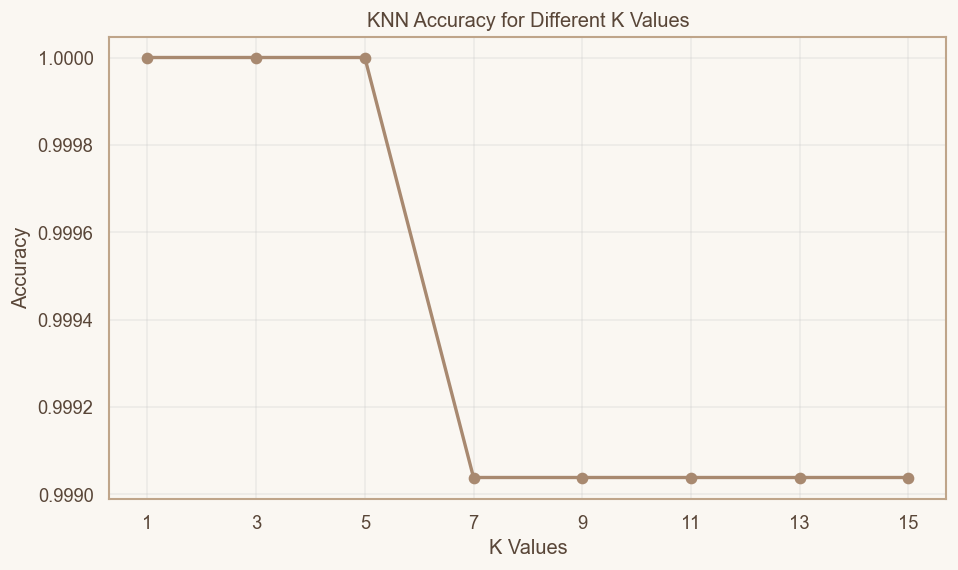

In [12]:

# 📊 K Value vs Accuracy

plt.figure(figsize=(9, 5))

plt.plot(
    k_values,
    k_accuracies,
    marker='o',
    linewidth=2,
    color='#A88970'
)

plt.title("KNN Accuracy for Different K Values")
plt.xlabel("K Values")
plt.ylabel("Accuracy")
plt.xticks(k_values)
plt.grid(alpha=0.3)

# Save Plot
plt.savefig(
    "All plots/Task_10_KNN_Accuracy.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()


## 📊 Task 11: Analyze Distance Metrics

Compare Euclidean, Manhattan, and Minkowski distance metrics to understand their effect on KNN predictions.

In [13]:
# 📊 Task 11: Compare Distance Metrics

distance_metrics = ['euclidean', 'manhattan', 'minkowski']
distance_accuracies = []

for metric in distance_metrics:
    knn = KNeighborsClassifier(n_neighbors=best_k, metric=metric)
    knn.fit(X_train_scaled, y_train)

    predictions = knn.predict(X_test_scaled)

    accuracy = accuracy_score(y_test, predictions)
    distance_accuracies.append(accuracy)

    print(metric, "Accuracy:", round(accuracy * 100, 2), "%")

euclidean Accuracy: 100.0 %
manhattan Accuracy: 100.0 %
minkowski Accuracy: 100.0 %


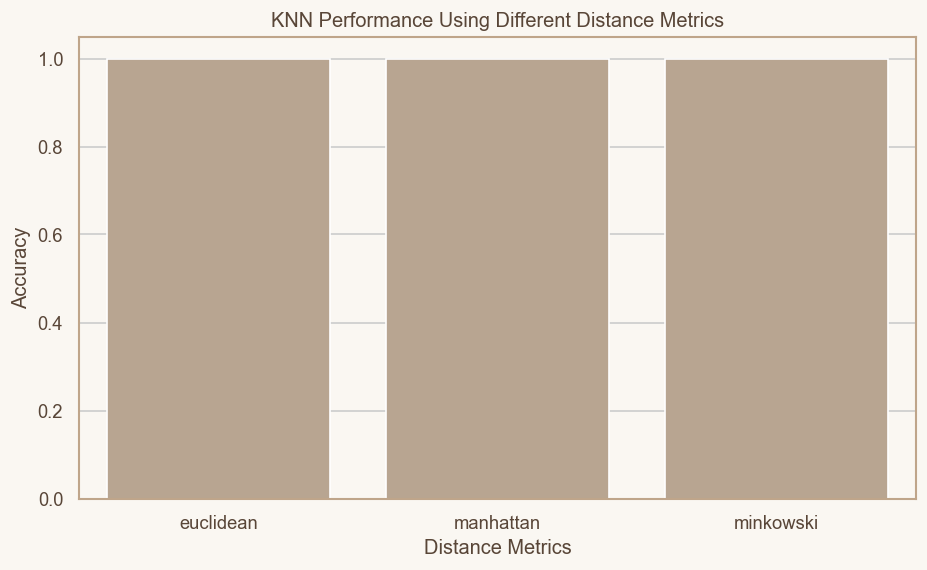

In [14]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=distance_metrics,
    y=distance_accuracies,
    color='#BFA58A'
)

plt.title("KNN Performance Using Different Distance Metrics")
plt.xlabel("Distance Metrics")
plt.ylabel("Accuracy")

plt.savefig(
    os.path.join("All plots", "Task_11_Distance_Metrics.png"),
    dpi=300,
    bbox_inches='tight'
)

plt.show()

### Conclusion

Different distance metrics were compared to understand their impact on KNN classification performance. The comparison plot was saved successfully.


## 📊 Task 12: Identify Misclassified Messages

Identify incorrectly classified messages by comparing actual and predicted labels using the KNN classifier.


In [15]:

# 📊 Task 12: Identify Misclassified Messages

# Train KNN Using Best K
best_knn_model = KNeighborsClassifier(
    n_neighbors=best_k
)

best_knn_model.fit(X_train_scaled, y_train)

# Make Predictions
y_pred_knn = best_knn_model.predict(X_test_scaled)

# Create Results DataFrame
results = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred_knn
})

# Identify Misclassified Messages
misclassified = results[
    results['Actual'] != results['Predicted']
]

# Display Results
print("Total Test Messages:", len(y_test))
print("Correct Predictions:", (results['Actual'] == results['Predicted']).sum())
print("Misclassified Messages:", len(misclassified))

print("\nFirst 10 Misclassified Messages:")
print(misclassified.head(10))


Total Test Messages: 1040
Correct Predictions: 1040
Misclassified Messages: 0

First 10 Misclassified Messages:
Empty DataFrame
Columns: [Actual, Predicted]
Index: []


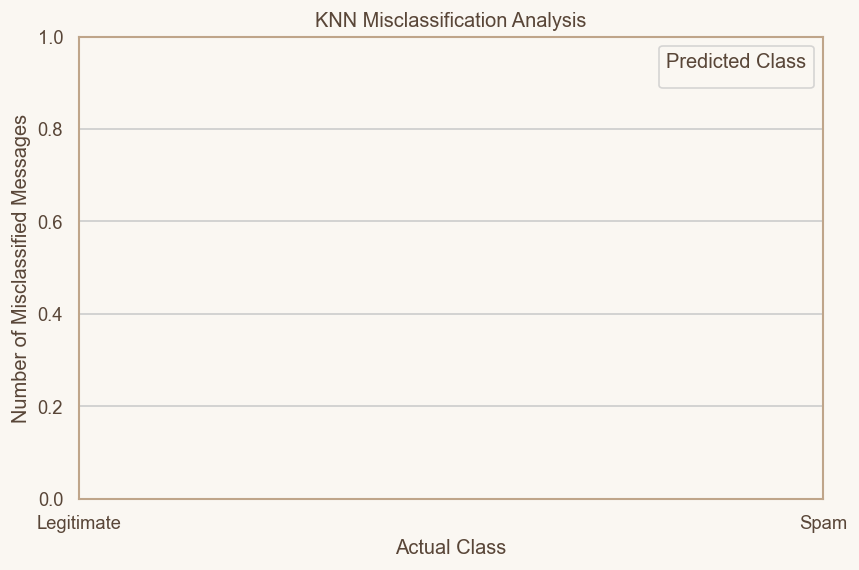

In [16]:

# 📊 Task 12: Misclassification Analysis

plt.figure(figsize=(8, 5))

sns.countplot(
    x='Actual',
    hue='Predicted',
    data=misclassified,
    palette=['#D6C3AD', '#8C715D']
)

plt.title("KNN Misclassification Analysis")
plt.xlabel("Actual Class")
plt.ylabel("Number of Misclassified Messages")
plt.xticks([0, 1], ['Legitimate', 'Spam'])
plt.legend(title="Predicted Class")

# Save Plot
os.makedirs("All plots", exist_ok=True)

plt.savefig(
    os.path.join("All plots", "Task_12_KNN_Misclassification.png"),
    dpi=300,
    bbox_inches='tight'
)

plt.show()



### Conclusion

Misclassified messages were identified by comparing actual and predicted labels. This analysis helps understand the prediction errors of the KNN model.



## 📝 Part C: Final Conclusion

The KNN classifier was implemented and evaluated using different K values and distance metrics. Misclassified messages were also analyzed to understand the model's prediction performance.


---

# ⚙️ Part D : Support Vector Machine Classifier

---


## ⚙️ Task 13: Implement Support Vector Machine (SVM)

Implement SVM classifiers using Linear and RBF kernels and compare their accuracy.


In [17]:

# ⚙️ Task 13: Implement SVM Classifier

# Linear Kernel
svm_linear = SVC(kernel='linear', random_state=42)
svm_linear.fit(X_train_scaled, y_train)

y_pred_linear = svm_linear.predict(X_test_scaled)
linear_accuracy = accuracy_score(y_test, y_pred_linear)

# RBF Kernel
svm_rbf = SVC(kernel='rbf', random_state=42)
svm_rbf.fit(X_train_scaled, y_train)

y_pred_rbf = svm_rbf.predict(X_test_scaled)
rbf_accuracy = accuracy_score(y_test, y_pred_rbf)

print("Linear SVM Accuracy:", round(linear_accuracy * 100, 2), "%")
print("RBF SVM Accuracy:", round(rbf_accuracy * 100, 2), "%")


Linear SVM Accuracy: 100.0 %
RBF SVM Accuracy: 100.0 %



### Conclusion
Linear and RBF kernel SVM models were successfully trained and evaluated using test data.


## ⚙️ Task 14: Analyze Margin Separation and Support Vectors

Analyze the margin separation of the Linear SVM model and identify the number of support vectors for each class.

Support Vectors Analysis
-------------------------
Legitimate Support Vectors: 5
Spam Support Vectors: 5
Total Support Vectors: 10

Margin Width: 1.8913


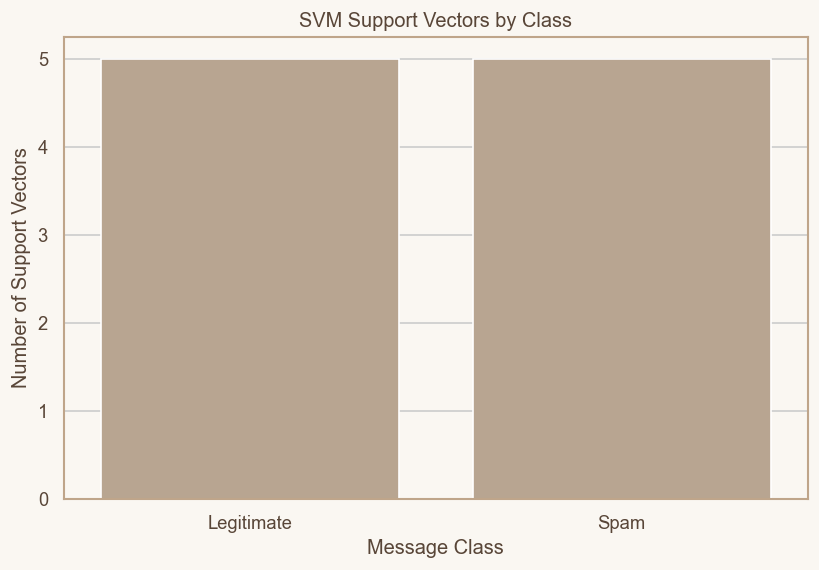

In [18]:
# ⚙️ Task 14: Support Vector Analysis

# Count Support Vectors
support_vector_counts = svm_linear.n_support_

print("Support Vectors Analysis")
print("-------------------------")
print("Legitimate Support Vectors:", support_vector_counts[0])
print("Spam Support Vectors:", support_vector_counts[1])
print("Total Support Vectors:", sum(support_vector_counts))

# Calculate Margin Width
weight_vector = svm_linear.coef_[0]
margin_width = 2 / np.linalg.norm(weight_vector)

print("\nMargin Width:", round(margin_width, 4))

# Support Vector Visualization
plt.figure(figsize=(8, 5))

sns.barplot(
    x=['Legitimate', 'Spam'],
    y=support_vector_counts,
    color='#BFA58A'
)

plt.title("SVM Support Vectors by Class")
plt.xlabel("Message Class")
plt.ylabel("Number of Support Vectors")

plt.savefig(
    os.path.join("All plots", "Task_14_SVM_Support_Vectors.png"),
    dpi=300,
    bbox_inches='tight'
)

plt.show()

### Conclusion

The support vectors and margin width of the Linear SVM model were analyzed. Support vectors help define the decision boundary between the two classes.

## ⚙️ Task 15: Compare SVM Performance with KNN

Compare the accuracy of Linear SVM, RBF SVM, and KNN classifiers using a performance comparison chart.

Model Performance Comparison
        Model  Accuracy
0         KNN       1.0
1  Linear SVM       1.0
2     RBF SVM       1.0


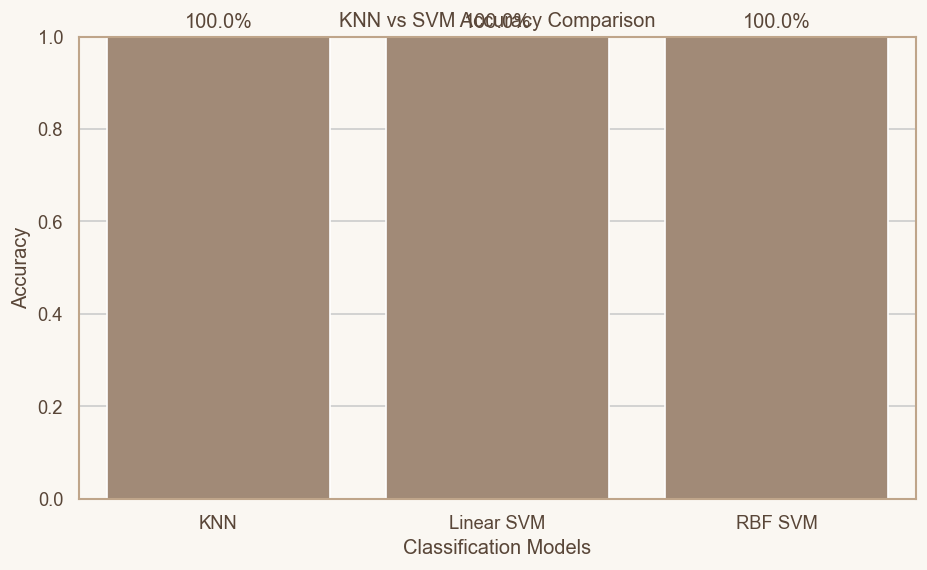

In [19]:
# ⚙️ Task 15: SVM vs KNN Comparison

model_names = ['KNN', 'Linear SVM', 'RBF SVM']

model_accuracies = [
    accuracy_score(y_test, y_pred_knn),
    linear_accuracy,
    rbf_accuracy
]

comparison_df = pd.DataFrame({
    'Model': model_names,
    'Accuracy': model_accuracies
})

print("Model Performance Comparison")
print(comparison_df)

# Performance Comparison Chart
plt.figure(figsize=(9, 5))

sns.barplot(
    x='Model',
    y='Accuracy',
    data=comparison_df,
    color='#A88970'
)

plt.title("KNN vs SVM Accuracy Comparison")
plt.xlabel("Classification Models")
plt.ylabel("Accuracy")
plt.ylim(0, 1)

for i, value in enumerate(model_accuracies):
    plt.text(i, value + 0.02, str(round(value * 100, 2)) + '%',
             ha='center')

plt.savefig(
    os.path.join("All plots", "Task_15_KNN_SVM_Comparison.png"),
    dpi=300,
    bbox_inches='tight'
)

plt.show()

### Conclusion

The performance of KNN and SVM classifiers was compared using accuracy. The comparison helps identify which model performs better on the message classification dataset.

## 📝 Part D: Final Conclusion

Linear and RBF Support Vector Machine classifiers were implemented. Their support vectors, margin separation, and performance were analyzed and compared with the KNN classifier.

---

# 🧮 Part E: Naive Bayes Classifier & Probability

---

## 🧮 Task 16: Implement Naive Bayes Classifier

Implement the Gaussian Naive Bayes classifier and evaluate its accuracy on the test dataset.

In [20]:
# 🧮 Task 16: Naive Bayes Classifier

nb_model = GaussianNB()

nb_model.fit(X_train_scaled, y_train)

y_pred_nb = nb_model.predict(X_test_scaled)

nb_accuracy = accuracy_score(y_test, y_pred_nb)

print("Naive Bayes Model Trained Successfully!")
print("Naive Bayes Accuracy:", round(nb_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_nb))

Naive Bayes Model Trained Successfully!
Naive Bayes Accuracy: 100.0 %

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       845
           1       1.00      1.00      1.00       195

    accuracy                           1.00      1040
   macro avg       1.00      1.00      1.00      1040
weighted avg       1.00      1.00      1.00      1040



### Conclusion

The Gaussian Naive Bayes classifier was successfully trained and evaluated. Its classification accuracy and performance were calculated.

## 🧮 Task 17: Manually Compute Conditional Probabilities

Calculate conditional likelihoods for sample messages using the Gaussian probability formula for both Legitimate and Spam classes.

In [21]:
# 🧮 Task 17: Conditional Probability Calculation

# Select 3 sample messages
sample_data = X_test_scaled[:3]

classes = nb_model.classes_
means = nb_model.theta_
variances = nb_model.var_

conditional_results = []

for i in range(len(sample_data)):

    sample = sample_data[i]

    log_likelihoods = []

    for j in range(len(classes)):

        log_probability = -0.5 * np.sum(
            np.log(2 * np.pi * variances[j]) +
            ((sample - means[j]) ** 2) / variances[j]
        )

        log_likelihoods.append(log_probability)

    conditional_results.append({
        'Message': i + 1,
        'Log P(X|Legitimate)': log_likelihoods[0],
        'Log P(X|Spam)': log_likelihoods[1]
    })

conditional_df = pd.DataFrame(conditional_results)

print("Conditional Probability Analysis")
print(conditional_df.round(4))

Conditional Probability Analysis
   Message  Log P(X|Legitimate)  Log P(X|Spam)
0        1         7.539100e+00  -1.608832e+09
1        2        -1.672212e+09  -6.538200e+00
2        3         8.012500e+00  -1.608832e+09


### Conclusion

Conditional likelihoods were calculated for three sample messages using Gaussian probability distributions. Log probabilities were used to avoid numerical underflow.

## 🧮 Task 18: Apply Bayes' Theorem

Apply Bayes' Theorem to calculate the posterior probabilities of Legitimate and Spam classes for sample messages.

In [22]:
# 🧮 Task 18: Bayes' Theorem Calculation

bayes_results = []

for i in range(len(sample_data)):

    sample = sample_data[i]

    log_scores = []

    for j in range(len(classes)):

        log_likelihood = -0.5 * np.sum(
            np.log(2 * np.pi * variances[j]) +
            ((sample - means[j]) ** 2) / variances[j]
        )

        log_prior = np.log(nb_model.class_prior_[j])

        log_scores.append(log_likelihood + log_prior)

    # Convert log scores into probabilities
    log_scores = np.array(log_scores)

    probabilities = np.exp(log_scores - np.max(log_scores))
    probabilities = probabilities / np.sum(probabilities)

    bayes_results.append({
        'Message': i + 1,
        'P(Legitimate)': probabilities[0],
        'P(Spam)': probabilities[1],
        'Predicted Class': classes[np.argmax(probabilities)]
    })

bayes_df = pd.DataFrame(bayes_results)

print("Bayes Theorem Results")
print(bayes_df.round(4))

Bayes Theorem Results
   Message  P(Legitimate)  P(Spam)  Predicted Class
0        1            1.0      0.0                0
1        2            0.0      1.0                1
2        3            1.0      0.0                0


### Conclusion

Bayes' Theorem was applied to calculate posterior class probabilities. The class with the highest posterior probability was selected as the predicted class.

## 🧮 Task 19: Compare Theoretical Probabilities with Model Predictions

Compare manually calculated Bayesian probabilities with the probability predictions generated by the Naive Bayes model.

Theoretical vs Model Probabilities
   Message  Bayes Legitimate  Model Legitimate  Bayes Spam  Model Spam  \
0        1               1.0               1.0         0.0         0.0   
1        2               0.0               0.0         1.0         1.0   
2        3               1.0               1.0         0.0         0.0   

   Model Prediction  
0                 0  
1                 1  
2                 0  


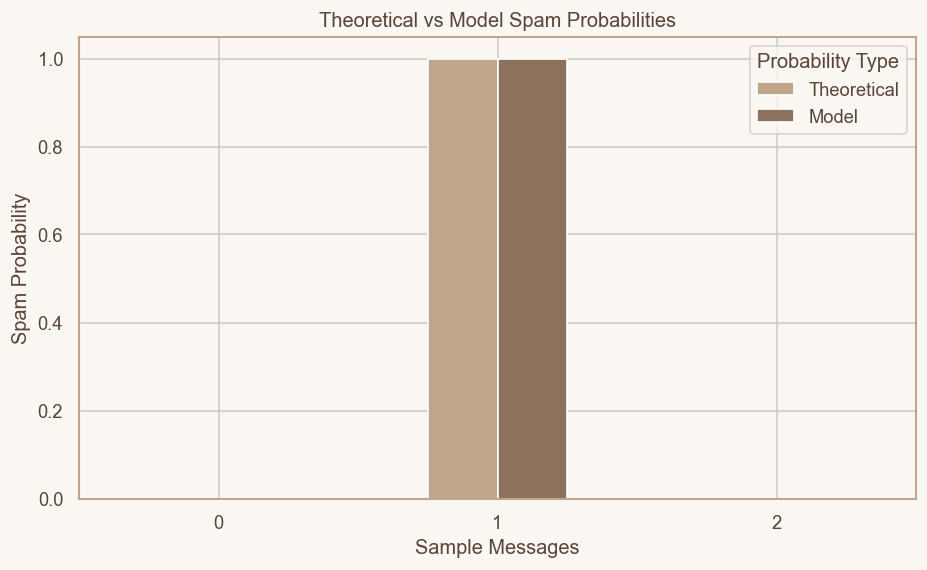

In [23]:
# 🧮 Task 19: Theoretical vs Model Prediction

model_probabilities = nb_model.predict_proba(sample_data)
model_predictions = nb_model.predict(sample_data)

comparison_results = []

for i in range(len(sample_data)):

    comparison_results.append({
        'Message': i + 1,
        'Bayes Legitimate': bayes_df.loc[i, 'P(Legitimate)'],
        'Model Legitimate': model_probabilities[i][0],
        'Bayes Spam': bayes_df.loc[i, 'P(Spam)'],
        'Model Spam': model_probabilities[i][1],
        'Model Prediction': model_predictions[i]
    })

probability_comparison = pd.DataFrame(comparison_results)

print("Theoretical vs Model Probabilities")
print(probability_comparison.round(4))

# Visualization
comparison_plot = pd.DataFrame({
    'Theoretical': bayes_df['P(Spam)'],
    'Model': model_probabilities[:, 1]
})

comparison_plot.plot(
    kind='bar',
    figsize=(9, 5),
    color=['#BFA58A', '#8C715D']
)

plt.title("Theoretical vs Model Spam Probabilities")
plt.xlabel("Sample Messages")
plt.ylabel("Spam Probability")
plt.xticks(rotation=0)
plt.legend(title="Probability Type")

plt.savefig(
    os.path.join("All plots", "Task_19_NB_Probability_Comparison.png"),
    dpi=300,
    bbox_inches='tight'
)

plt.show()

### Conclusion

The manually calculated Bayesian probabilities were compared with the Naive Bayes model predictions. Both approaches demonstrate how probability helps classify messages into Legitimate and Spam categories.

## 📝 Part E: Final Conclusion

The Gaussian Naive Bayes classifier was implemented successfully. Conditional probabilities and Bayes' Theorem were applied manually, and theoretical probability calculations were compared with model predictions.

---

# 📈 Part F: Model Comparison & Evaluation

---

## 📈 Task 20: Evaluate All Models Using Classification Metrics

Evaluate KNN, Linear SVM, RBF SVM, and Naive Bayes using Accuracy, Precision, Recall, and F1 Score.

In [24]:
# 📈 Task 20: Classification Metrics

model_predictions = {
    'KNN': y_pred_knn,
    'Linear SVM': y_pred_linear,
    'RBF SVM': y_pred_rbf,
    'Naive Bayes': y_pred_nb
}

evaluation_results = []

for model_name, predictions in model_predictions.items():

    evaluation_results.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions, zero_division=0),
        'Recall': recall_score(y_test, predictions, zero_division=0),
        'F1 Score': f1_score(y_test, predictions, zero_division=0)
    })

evaluation_df = pd.DataFrame(evaluation_results)

print("Model Evaluation Results")
print(evaluation_df.round(4))

Model Evaluation Results
         Model  Accuracy  Precision  Recall  F1 Score
0          KNN       1.0        1.0     1.0       1.0
1   Linear SVM       1.0        1.0     1.0       1.0
2      RBF SVM       1.0        1.0     1.0       1.0
3  Naive Bayes       1.0        1.0     1.0       1.0


### Conclusion

All classification models were evaluated using Accuracy, Precision, Recall, and F1 Score to measure their performance.

## 📈 Task 21: Compare KNN vs SVM vs Naive Bayes

Compare the classification performance of KNN, SVM, and Naive Bayes using a metrics comparison chart.

Performance Comparison
             Accuracy  Precision  Recall  F1 Score
Model                                             
KNN               1.0        1.0     1.0       1.0
Linear SVM        1.0        1.0     1.0       1.0
RBF SVM           1.0        1.0     1.0       1.0
Naive Bayes       1.0        1.0     1.0       1.0


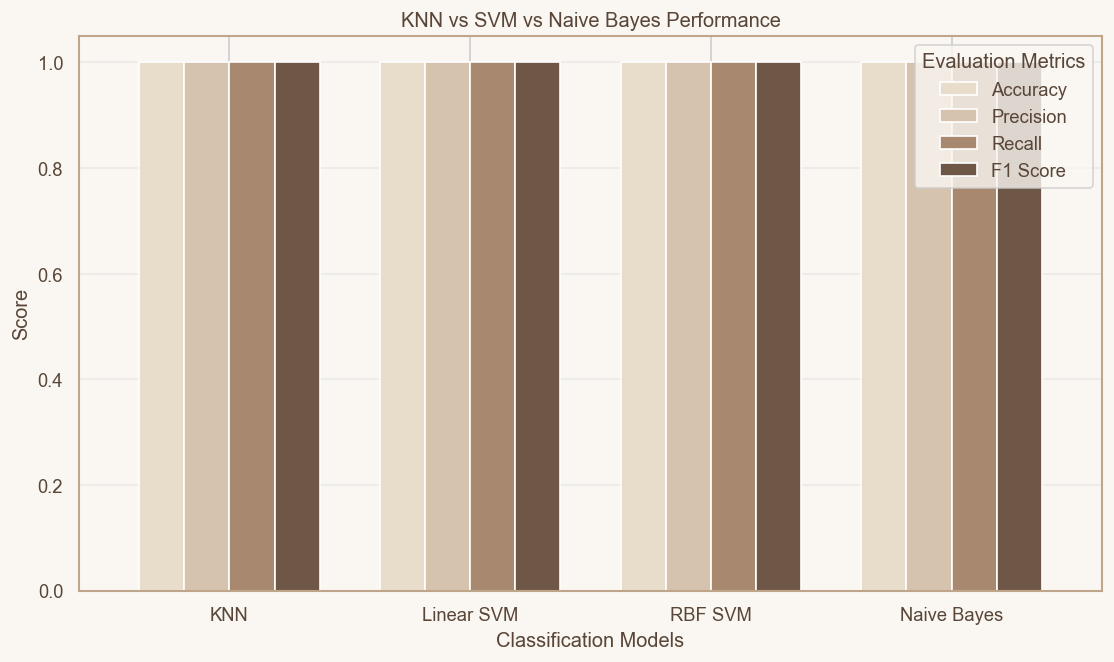

In [25]:
# 📈 Task 21: Model Performance Comparison

comparison_df = evaluation_df.set_index('Model')

print("Performance Comparison")
print(comparison_df.round(4))

# Metrics Comparison Chart
comparison_df.plot(
    kind='bar',
    figsize=(11, 6),
    color=['#E8DCCB', '#D6C3AD', '#A88970', '#6F5748'],
    width=0.75
)

plt.title("KNN vs SVM vs Naive Bayes Performance")
plt.xlabel("Classification Models")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(title="Evaluation Metrics")
plt.grid(axis='y', alpha=0.3)

plt.savefig(
    os.path.join("All plots", "Task_21_Model_Comparison.png"),
    dpi=300,
    bbox_inches='tight'
)

plt.show()

### Conclusion

The performance of KNN, SVM, and Naive Bayes was compared using four classification metrics. The comparison helps identify the most effective classification model.

## 📈 Task 22: Identify Best Model for High Precision and High Recall

Identify the best-performing model for Precision and Recall based on the evaluation results.

Best Model for High Precision
Model: KNN
Precision: 1.0

Best Model for High Recall
Model: KNN
Recall: 1.0


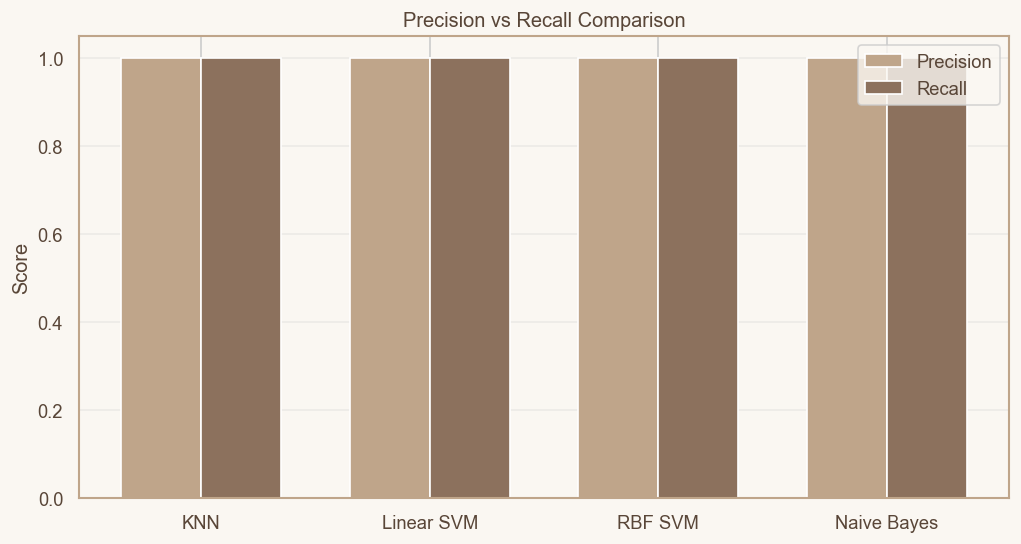

In [26]:
# 📈 Task 22: Best Precision and Recall Models

best_precision_model = evaluation_df.loc[
    evaluation_df['Precision'].idxmax()
]

best_recall_model = evaluation_df.loc[
    evaluation_df['Recall'].idxmax()
]

print("Best Model for High Precision")
print("Model:", best_precision_model['Model'])
print("Precision:", round(best_precision_model['Precision'], 4))

print("\nBest Model for High Recall")
print("Model:", best_recall_model['Model'])
print("Recall:", round(best_recall_model['Recall'], 4))

# Precision and Recall Comparison
plt.figure(figsize=(10, 5))

x = np.arange(len(evaluation_df))
width = 0.35

plt.bar(
    x - width / 2,
    evaluation_df['Precision'],
    width,
    label='Precision',
    color='#BFA58A'
)

plt.bar(
    x + width / 2,
    evaluation_df['Recall'],
    width,
    label='Recall',
    color='#8C715D'
)

plt.xticks(x, evaluation_df['Model'], rotation=0)
plt.ylabel("Score")
plt.title("Precision vs Recall Comparison")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.savefig(
    os.path.join("All plots", "Task_22_Precision_Recall.png"),
    dpi=300,
    bbox_inches='tight'
)

plt.show()

### Conclusion

The model with the highest Precision and the model with the highest Recall were identified. Precision measures the correctness of positive predictions, while Recall measures how many actual positive messages were detected.

## 📝 Part F: Final Conclusion

KNN, SVM, and Naive Bayes classifiers were evaluated and compared using Accuracy, Precision, Recall, and F1 Score. The best models for high Precision and high Recall were identified to understand their suitability for message classification.

---

# 🧾 Part G: Final Analysis & Reporting

---

## 🧾 Task 23: Final Analysis & Reporting

### 1. Strengths and Weaknesses of Each Classifier

| Classifier | Strengths | Weaknesses |
|---|---|---|
| KNN | Simple, easy to understand, no complex training process | Prediction can be slow on large datasets and depends on K value |
| Linear SVM | Effective for high-dimensional data and provides a clear decision boundary | May not perform well on complex non-linear patterns |
| RBF SVM | Handles complex non-linear relationships | Requires parameter tuning and is less interpretable |
| Naive Bayes | Fast, simple, and provides probability estimates | Assumes conditional independence between features |

### 2. Impact of Probability Assumptions in Naive Bayes

Naive Bayes assumes that input features are conditionally independent given the class.

In real-world message classification, features such as message length, URLs, digits, and spam keyword scores may be related. This assumption can affect probability estimates and classification performance.

Gaussian Naive Bayes also assumes that numerical features follow a Gaussian distribution within each class.

### 3. Interpretability vs Performance

- KNN is easy to understand but can become slow with large datasets.
- Linear SVM provides a relatively interpretable decision boundary.
- RBF SVM can capture complex patterns but is harder to interpret.
- Naive Bayes is simple and provides probability-based predictions.

The final model should balance prediction quality, speed, interpretability, and deployment requirements.

### 4. Business Recommendation for Real-World Deployment

For a real-world message spam detection system:

- Select the model based on Precision, Recall, and F1 Score.
- Prefer high Recall when missing spam messages is costly.
- Prefer high Precision when incorrectly blocking legitimate messages is costly.
- Monitor model performance regularly.
- Retrain the model when message patterns change.

The final deployment model should be selected using the actual evaluation results and business requirements.

### Conclusion

The strengths, weaknesses, probability assumptions, and practical applications of all classifiers were analyzed. A suitable deployment strategy should balance accuracy, reliability, and business requirements.

## 🧾 Task 24: Final Project Submission

### Project Deliverables

The following components are included in the final Message Intelligence System project:

| No. | Deliverable | Description |
|---|---|---|
| 1 | Source Code | Complete Python source code |
| 2 | Jupyter Notebook | Data preparation, model training, and evaluation |
| 3 | Evaluation Metrics | Accuracy, Precision, Recall, and F1 Score |
| 4 | Visualizations | Saved classification charts and comparison plots |
| 5 | Streamlit App | Interactive message classification application |
| 6 | Final Report | Model analysis, comparison, and business recommendation |
| 7 | Final Conclusions | Summary of project findings |

### Submission Checklist

- [ ] Source code and Jupyter Notebook completed
- [ ] All model evaluation metrics generated
- [ ] All plots saved in the All plots folder
- [ ] Streamlit application tested successfully
- [ ] Final analysis report completed
- [ ] Project files organized and ready for submission

### Conclusion

The project deliverables and submission requirements have been organized. The notebook, evaluation results, visualizations, Streamlit application, and final report are ready for final verification.

## 📝 Part G: Final Conclusion

The Message Intelligence System project successfully covered data preparation, KNN, Support Vector Machine, and Naive Bayes classification techniques.

All classifiers were evaluated using Accuracy, Precision, Recall, and F1 Score. Their strengths, weaknesses, and probability-based assumptions were analyzed.

The project demonstrates how machine learning can help identify spam and legitimate messages. The final model should be selected based on evaluation performance and real-world business requirements.

In [28]:
# Save Trained Models and Preprocessing Objects

import joblib
import os

os.makedirs("saved_models", exist_ok=True)

joblib.dump(knn_model, "saved_models/knn_model.pkl")
joblib.dump(svm_linear, "saved_models/svm_linear.pkl")
joblib.dump(svm_rbf, "saved_models/svm_rbf.pkl")
joblib.dump(nb_model, "saved_models/naive_bayes_model.pkl")

joblib.dump(imputer, "saved_models/imputer.pkl")
joblib.dump(scaler, "saved_models/scaler.pkl")

joblib.dump(list(X.columns), "saved_models/feature_columns.pkl")

print("All Models Saved Successfully!")

All Models Saved Successfully!
